In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
cluster =  pd.read_csv("grova1.csv",header = None)

In [3]:
cluster.columns = ["X","Y","Vx","Vy","Vz"]

In [4]:
cluster

,X,Y,Vx,Vy,Vz
0,10.20,8.53,2.08,1.86,0.18
1,18.81,25.83,1.10,0.34,2.86
2,13.60,14.40,1.10,1.64,2.42
3,6.82,14.03,1.28,0.15,0.77
4,2.68,24.63,0.34,1.61,1.54
...,...,...,...,...,...
3295,19.18,9.12,4.79,5.84,4.42
3296,20.23,10.19,6.08,5.36,5.24
3297,17.42,11.01,4.42,5.14,5.01
3298,20.88,11.79,4.96,4.92,4.90


In [5]:
X = cluster["X"]
Y = cluster["Y"]
Vx = cluster["Vx"]
Vy = cluster["Vy"]
Vz = cluster["Vz"]

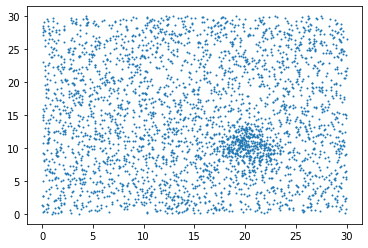

In [6]:
plt.scatter(cluster["X"],cluster["Y"], s = 1)

(0.0, 72.0)

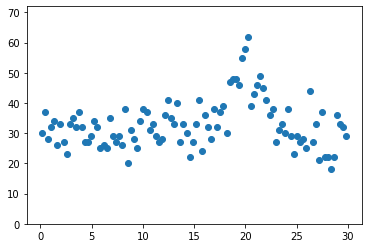

In [7]:
# ეს არ დაგვეხმარა არაფერში რადგან ბევრი ვარსკვლავია საშუალოს გასწვრივ, რომელიც არ ემთხვევა თავისთავად იმ ამპლიტუდას რომელსაც ვხედავთ. 
bins = 100

uniform_hist_X = np.histogram(X, bins)
edges = uniform_hist_X[1]
centers = (edges[:-1] + edges[1:])/2
plt.scatter(centers, uniform_hist_X[0])
plt.ylim(0,max(uniform_hist_X[0]) + 10)

(0.0, 77.0)

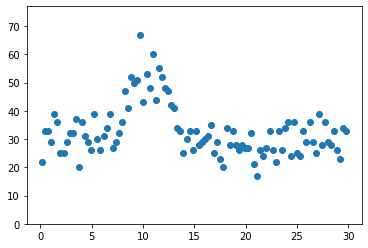

In [8]:
# იგივე Y-ზეც. 
uniform_hist_Y = np.histogram(Y, bins)
edges1 = uniform_hist_Y[1]
centers1 = (edges1[:-1] + edges1[1:])/2
plt.scatter(centers1, uniform_hist_Y[0])
plt.ylim(0,max(uniform_hist_Y[0]) + 10)

In [9]:
def gauss(x, A, mu, sigma):
    return A * np.exp(-(x - mu)**2/(2*sigma**2))

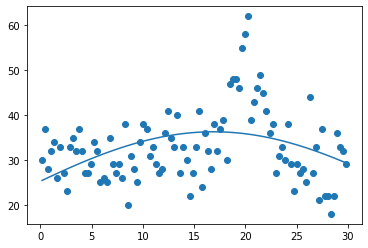

In [10]:
# ამ ვარსკვლავების სიბევრის გამო, ვერ აღიქვამს სწორად პიკს. ცოტათი გადახარა, თუმცა ჩემთვის არაფრისმომცემია.
popt, pcov = curve_fit(gauss, centers, uniform_hist_X[0], p0=[uniform_hist_X[0].max(), X.mean(), X.std()])
plt.scatter(centers, uniform_hist_X[0])
plt.plot(centers, gauss(centers, *popt))

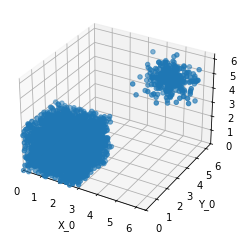

In [11]:
# გადავწყვიტე სიჩქარებიის მიხედვით გავფლიტრო ჯერ. 
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

X_0, Y_0, Z_0 = [0, 0], [0, 0], [0, 0]
ax.set_xlim([0, max(Vx)])
ax.set_ylim([0, max(Vy)])
ax.set_zlim([0, max(Vz)])
ax.set_xlabel('X_0')
ax.set_ylabel('Y_0')
ax.set_zlabel('Z_0')

ax.scatter(Vx,Vy,Vz)

In [12]:
cluster.describe()

,X,Y,Vx,Vy,Vz
count,3300.000000,3300.000000,3300.000000,3300.000000,3300.000000
mean,15.273594,14.384821,1.842697,1.808479,1.810027
std,8.351931,8.380039,1.290415,1.316524,1.306388
min,0.010000,0.010000,0.000000,0.000000,0.000000
25%,8.227500,8.070000,0.880000,0.820000,0.830000
50%,16.050000,12.985000,1.700000,1.640000,1.600000
75%,21.805000,21.662500,2.470000,2.450000,2.460000
max,30.000000,29.980000,6.490000,6.520000,6.340000


In [13]:
Vx.mode()
# ეს თავისთავად საშუალოზე ბევრად ახლოსაა, თუმცა 75% უფრო ახლოსაა. 

0    2.15
Name: Vx, dtype: float64

In [14]:
Vx.median()
#საერთოდ არ მაწყობს

1.7

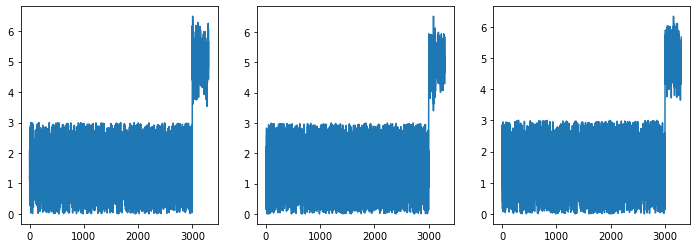

In [15]:
fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (12,4))
ax1.plot(Vx)
ax2.plot(Vy)
ax3.plot(Vz)

{'whiskers': [<matplotlib.lines.Line2D at 0x7f7b6aa9ddf0>,
 'caps': [<matplotlib.lines.Line2D at 0x7f7b6aaaa370>,
 'boxes': [<matplotlib.lines.Line2D at 0x7f7b6aa9db50>],
 'medians': [<matplotlib.lines.Line2D at 0x7f7b6aaaa8b0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7f7b6aaaab50>],
 'means': []}

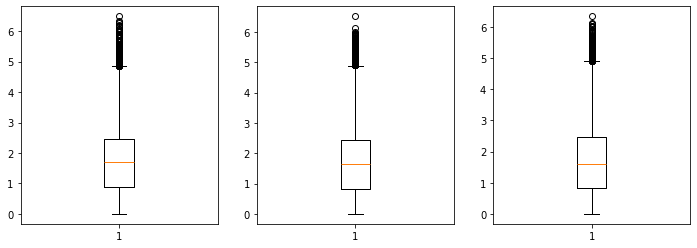

In [16]:
fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (12,4))
ax1.boxplot(Vx)
ax2.boxplot(Vy)
ax3.boxplot(Vz)

In [17]:
percentiles = pd.DataFrame()
for i in range(0,100,5):
    percentiles[f"{i}"] = [np.percentile(Vx,i), np.percentile(Vy,i), np.percentile(Vz,i)]

In [18]:
percentiles

,0,5,10,15,20,25,30,35,40,45,50,55,60,65,70,75,80,85,90,95
0,0.0,0.17,0.360,0.56,0.72,0.88,1.05,1.22,1.37,1.52,1.70,1.86,2.00,2.16,2.32,2.47,2.64,2.8,2.970,4.9000
1,0.0,0.14,0.320,0.49,0.66,0.82,0.99,1.13,1.31,1.48,1.64,1.80,1.97,2.13,2.28,2.45,2.62,2.8,2.961,4.9305
2,0.0,0.16,0.339,0.51,0.68,0.83,0.99,1.15,1.30,1.46,1.60,1.79,1.96,2.13,2.31,2.46,2.62,2.8,2.970,4.9305


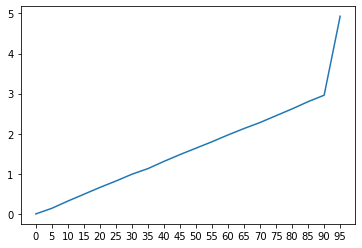

In [19]:
plt.plot(percentiles.loc[1])

In [20]:
percentiles

,0,5,10,15,20,25,30,35,40,45,50,55,60,65,70,75,80,85,90,95
0,0.0,0.17,0.360,0.56,0.72,0.88,1.05,1.22,1.37,1.52,1.70,1.86,2.00,2.16,2.32,2.47,2.64,2.8,2.970,4.9000
1,0.0,0.14,0.320,0.49,0.66,0.82,0.99,1.13,1.31,1.48,1.64,1.80,1.97,2.13,2.28,2.45,2.62,2.8,2.961,4.9305
2,0.0,0.16,0.339,0.51,0.68,0.83,0.99,1.15,1.30,1.46,1.60,1.79,1.96,2.13,2.31,2.46,2.62,2.8,2.970,4.9305


In [21]:
diff = pd.DataFrame()

for i in range(5,100,5):
    col_name = f"{i-5}% - {i}%"
    diff.loc[0, col_name] = percentiles.loc[0, str(i)] - percentiles.loc[0, str(i - 5)]
    diff.loc[1, col_name] = percentiles.loc[1, str(i)] - percentiles.loc[1, str(i - 5)]
    diff.loc[2, col_name] = percentiles.loc[2, str(i)] - percentiles.loc[2, str(i - 5)]

In [22]:
diff

,0% - 5%,5% - 10%,10% - 15%,15% - 20%,20% - 25%,25% - 30%,30% - 35%,35% - 40%,40% - 45%,45% - 50%,50% - 55%,55% - 60%,60% - 65%,65% - 70%,70% - 75%,75% - 80%,80% - 85%,85% - 90%,90% - 95%
0,0.17,0.190,0.200,0.16,0.16,0.17,0.17,0.15,0.15,0.18,0.16,0.14,0.16,0.16,0.15,0.17,0.16,0.170,1.9300
1,0.14,0.180,0.170,0.17,0.16,0.17,0.14,0.18,0.17,0.16,0.16,0.17,0.16,0.15,0.17,0.17,0.18,0.161,1.9695
2,0.16,0.179,0.171,0.17,0.15,0.16,0.16,0.15,0.16,0.14,0.19,0.17,0.17,0.18,0.15,0.16,0.18,0.170,1.9605


In [25]:
diff_max = max(diff)
diff_max

'90% - 95%'

In [ ]:
# აქ ვსვამ ხელით
Vx_cutoff = np.percentile(Vx,90)
Vy_cutoff = np.percentile(Vy,90)
Vz_cutoff = np.percentile(Vz,90)

In [28]:
Vy_cutoff

2.960999999999999

In [29]:
final_cluster = cluster[(cluster["Vx"] >= Vx_cutoff) & (cluster["Vy"] >= Vy_cutoff) & (cluster["Vz"] >= Vz_cutoff)]
final_cluster

,X,Y,Vx,Vy,Vz
3000,20.52,6.33,6.18,5.25,3.78
3001,17.91,12.87,4.39,5.32,4.92
3002,21.24,11.62,6.00,5.94,5.44
3003,18.76,9.67,4.84,5.03,4.75
3004,18.85,9.17,5.13,5.12,4.75
...,...,...,...,...,...
3295,19.18,9.12,4.79,5.84,4.42
3296,20.23,10.19,6.08,5.36,5.24
3297,17.42,11.01,4.42,5.14,5.01
3298,20.88,11.79,4.96,4.92,4.90


In [30]:
X_cluster = final_cluster["X"]
Y_cluster = final_cluster["Y"]

(0.0, 23.0)

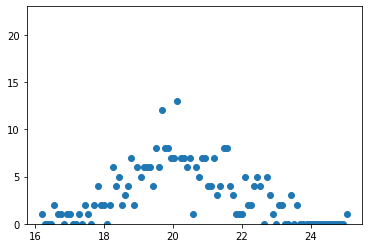

In [31]:
bins = 100

uniform_hist_X = np.histogram(X_cluster, bins)
edges = uniform_hist_X[1]
centers = (edges[:-1] + edges[1:])/2
plt.scatter(centers, uniform_hist_X[0])
plt.ylim(0,max(uniform_hist_X[0]) + 10)

(0.0, 24.0)

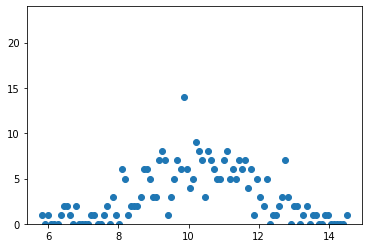

In [32]:
uniform_hist_Y = np.histogram(Y_cluster, bins)
edges1 = uniform_hist_Y[1]
centers1 = (edges1[:-1] + edges1[1:])/2
plt.scatter(centers1, uniform_hist_Y[0])
plt.ylim(0,max(uniform_hist_Y[0]) + 10)

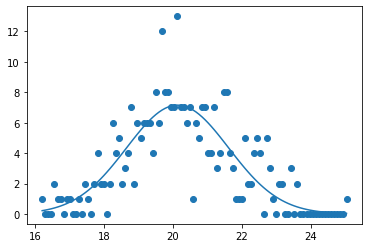

In [33]:
popt, pcov = curve_fit(gauss, centers, uniform_hist_X[0], p0=[uniform_hist_X[0].max(), X_cluster.mean(), X_cluster.std()])
plt.scatter(centers, uniform_hist_X[0])
plt.plot(centers, gauss(centers, *popt))

In [34]:
x_center = popt[1]

In [35]:
residuals = uniform_hist_X[0] - gauss(centers, *popt)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((uniform_hist_X[0] - uniform_hist_X[0].mean())**2)
r2 = 1 - ss_res / ss_tot
r2

0.6886650989456303

0.6481810085740409

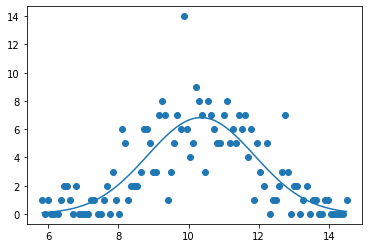

In [36]:
popt, pcov = curve_fit(gauss, centers1, uniform_hist_Y[0], p0=[uniform_hist_Y[0].max(), Y_cluster.mean(), Y_cluster.std()])
plt.scatter(centers1, uniform_hist_Y[0])
plt.plot(centers1, gauss(centers1, *popt))
residuals = uniform_hist_Y[0] - gauss(centers1, *popt)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((uniform_hist_Y[0] - uniform_hist_Y[0].mean())**2)
r2_y = 1 - ss_res / ss_tot
r2_y

In [37]:
y_center = popt[1]

In [38]:
print(x_center, y_center)

20.1381719806393 10.355700768449026


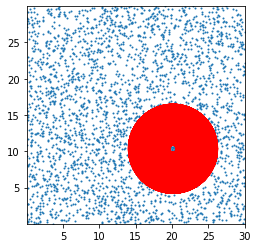

In [111]:
n = final_cluster.shape[0]

r = 0.5
n_circ = 150
t = np.linspace(-10*np.pi,10*np.pi,300)

plt.scatter(X, Y, s = 1)

for i in range(n_circ):
    R = r*np.sqrt(i+1)
    plt.plot(x_center+R*np.cos(t),y_center+R*np.sin(t),c = "r")
plt.xlim(X.min(), X.max())
plt.ylim(Y.min(), Y.max())
plt.gca().set_aspect("equal")

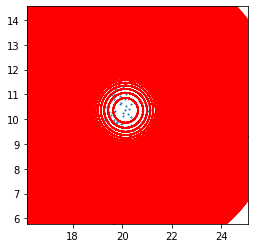

In [113]:
t = np.linspace(-10*np.pi,10*np.pi,300)

plt.scatter(X_cluster, Y_cluster, s = 1)

for i in range(n_circ):
    R = r*np.sqrt(i+1)
    plt.plot(x_center+R*np.cos(t),y_center+R*np.sin(t),c = "r")
plt.xlim(X_cluster.min(), X_cluster.max())
plt.ylim(Y_cluster.min(), Y_cluster.max())
plt.gca().set_aspect("equal")

In [119]:
counts = [0] * n_circ
for i in range(n_circ):
    for j in range(n):
        if (r*np.sqrt(i))**2<(X_cluster.iloc[j]-x_center)**2 + (Y_cluster.iloc[j]-y_center)**2<=(r*np.sqrt(i+1))**2:
            counts[i] = counts[i] + 1

In [120]:
sum(counts)

300

In [124]:
n_all = cluster.shape[0]
counts_full = [0] * n_circ
for i in range(n_circ):
    for j in range(n_all):
        if (r*np.sqrt(i))**2<(X.iloc[j]-x_center)**2 + (Y.iloc[j]-y_center)**2<=(r*np.sqrt(i+1))**2:
            counts_full[i] = counts_full[i] + 1

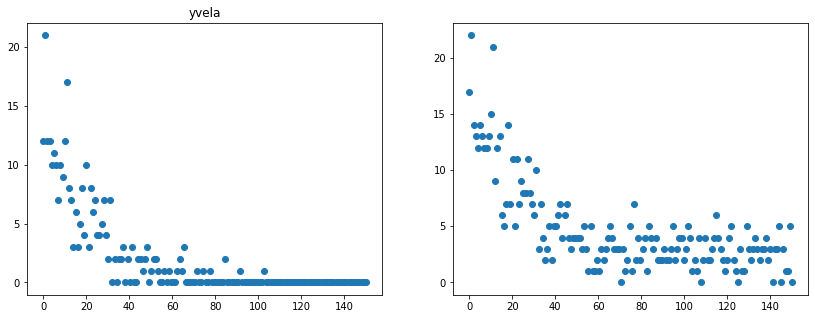

In [132]:
fig, (ax1,ax2) = plt.subplots(1, 2, figsize = (14,5))
ax1.scatter(np.linspace(0,n_circ,n_circ),counts)
ax1.set_title("clusteri")
ax2.scatter(np.linspace(0,n_circ,n_circ),counts_full)
ax1.set_title("yvela")

plt.show()